In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from datasets import load_dataset

ds = load_dataset("google-research-datasets/go_emotions", "simplified")
names = ds['train'].features['labels'].feature.names
print(len(names), names)

# Keep single-label comments only, add a plain int 'label' column
ds = ds.filter(lambda x: len(x['labels']) == 1)
ds = ds.map(lambda x: {'label': x['labels'][0]})

train_df, val_df, test_df = (ds[s].to_pandas() for s in ['train', 'validation', 'test'])
print(len(train_df), len(val_df), len(test_df))

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

... (8 outputs left out)

Map:   0%|          | 0/36308 [00:00<?, ? examples/s]

Map:   0%|          | 0/4548 [00:00<?, ? examples/s]

Map:   0%|          | 0/4590 [00:00<?, ? examples/s]

36308 4548 4590


In [2]:
counts = pd.DataFrame({
    'train': train_df.label.value_counts().sort_index(),
    'test':  test_df.label.value_counts().sort_index(),
})
counts.index = names
counts.sort_values('train', ascending=False)

,train,test
neutral,12823,1606
admiration,2710,348
approval,1873,236
gratitude,1857,260
amusement,1652,186
annoyance,1451,194
love,1427,160
disapproval,1402,195
curiosity,1389,176
anger,1025,131


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(train_df.text)
Xva = vec.transform(val_df.text)
Xte = vec.transform(test_df.text)

#clf = LogisticRegression(class_weight='balanced', max_iter=2000)
#clf.fit(Xtr, train_df.label)

In [9]:
scores = {}
for C in [0.5, 1, 2, 4, 8, 16]:
    m = LogisticRegression(C=C, class_weight='balanced', max_iter=2000)
    m.fit(Xtr, train_df.label)
    scores[C] = f1_score(val_df.label, m.predict(Xva), average='macro')
    print(f"C={C}: val macro-F1 = {scores[C]:.4f}")

best_C = max(scores, key=scores.get)
print("Best C:", best_C)

C=0.5: val macro-F1 = 0.4122
C=1: val macro-F1 = 0.4333
C=2: val macro-F1 = 0.4403
C=4: val macro-F1 = 0.4445
C=8: val macro-F1 = 0.4496
C=16: val macro-F1 = 0.4456
Best C: 8


In [10]:
clf = LogisticRegression(C=best_C, class_weight='balanced', max_iter=2000)
clf.fit(Xtr, train_df.label)

LogisticRegression(C=8, class_weight='balanced', max_iter=2000)

In [11]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

ckpt = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(ckpt)

tds = ds.map(lambda b: tok(b['text'], truncation=True, max_length=64), batched=True)
tds = tds.remove_columns(['labels', 'id'])   # keep the int 'label' column

model = AutoModelForSequenceClassification.from_pretrained(
    ckpt, num_labels=len(names),
    id2label=dict(enumerate(names)), label2id={n: i for i, n in enumerate(names)})

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {'macro_f1': f1_score(p.label_ids, preds, average='macro'),
            'accuracy': (preds == p.label_ids).mean()}

args = TrainingArguments(
    output_dir='distilbert-goemotions',
    eval_strategy='epoch', save_strategy='epoch',
    load_best_model_at_end=True, metric_for_best_model='macro_f1',
    learning_rate=5e-5, per_device_train_batch_size=32, per_device_eval_batch_size=64,
    num_train_epochs=3, weight_decay=0.01, fp16=True,
    save_total_limit=1, report_to='none')

trainer = Trainer(model=model, args=args,
                  train_dataset=tds['train'], eval_dataset=tds['validation'],
                  data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=compute_metrics)
trainer.train()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/36308 [00:00<?, ? examples/s]

Map:   0%|          | 0/4548 [00:00<?, ? examples/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1704, training_loss=2.484910293364189, metrics={'train_runtime': 274.1055, 'train_samples_per_second': 397.38, 'train_steps_per_second': 6.217, 'total_flos': 1075217707672800.0, 'train_loss': 2.484910293364189, 'epoch': 3.0})

In [13]:
lr_pred   = clf.predict(Xte)
bert_pred = trainer.predict(tds['test']).predictions.argmax(-1)
y = test_df.label.values

In [14]:
support = np.bincount(y, minlength=len(names))
results = pd.DataFrame({
    'support':    support,
    'tfidf_lr':   f1_score(y, lr_pred,   average=None, labels=range(len(names)), zero_division=0),
    'distilbert': f1_score(y, bert_pred, average=None, labels=range(len(names)), zero_division=0),
}, index=names).round(3)

results.loc['MACRO'] = [support.sum(),
                        round(f1_score(y, lr_pred,   average='macro'), 3),
                        round(f1_score(y, bert_pred, average='macro'), 3)]
results.sort_values('support', ascending=False)

,support,tfidf_lr,distilbert
MACRO,4590.0,0.421,0.475
neutral,1606.0,0.554,0.693
admiration,348.0,0.613,0.692
gratitude,260.0,0.920,0.910
approval,236.0,0.293,0.412
disapproval,195.0,0.324,0.421
annoyance,194.0,0.214,0.283
amusement,186.0,0.765,0.816
curiosity,176.0,0.394,0.560
love,160.0,0.770,0.838


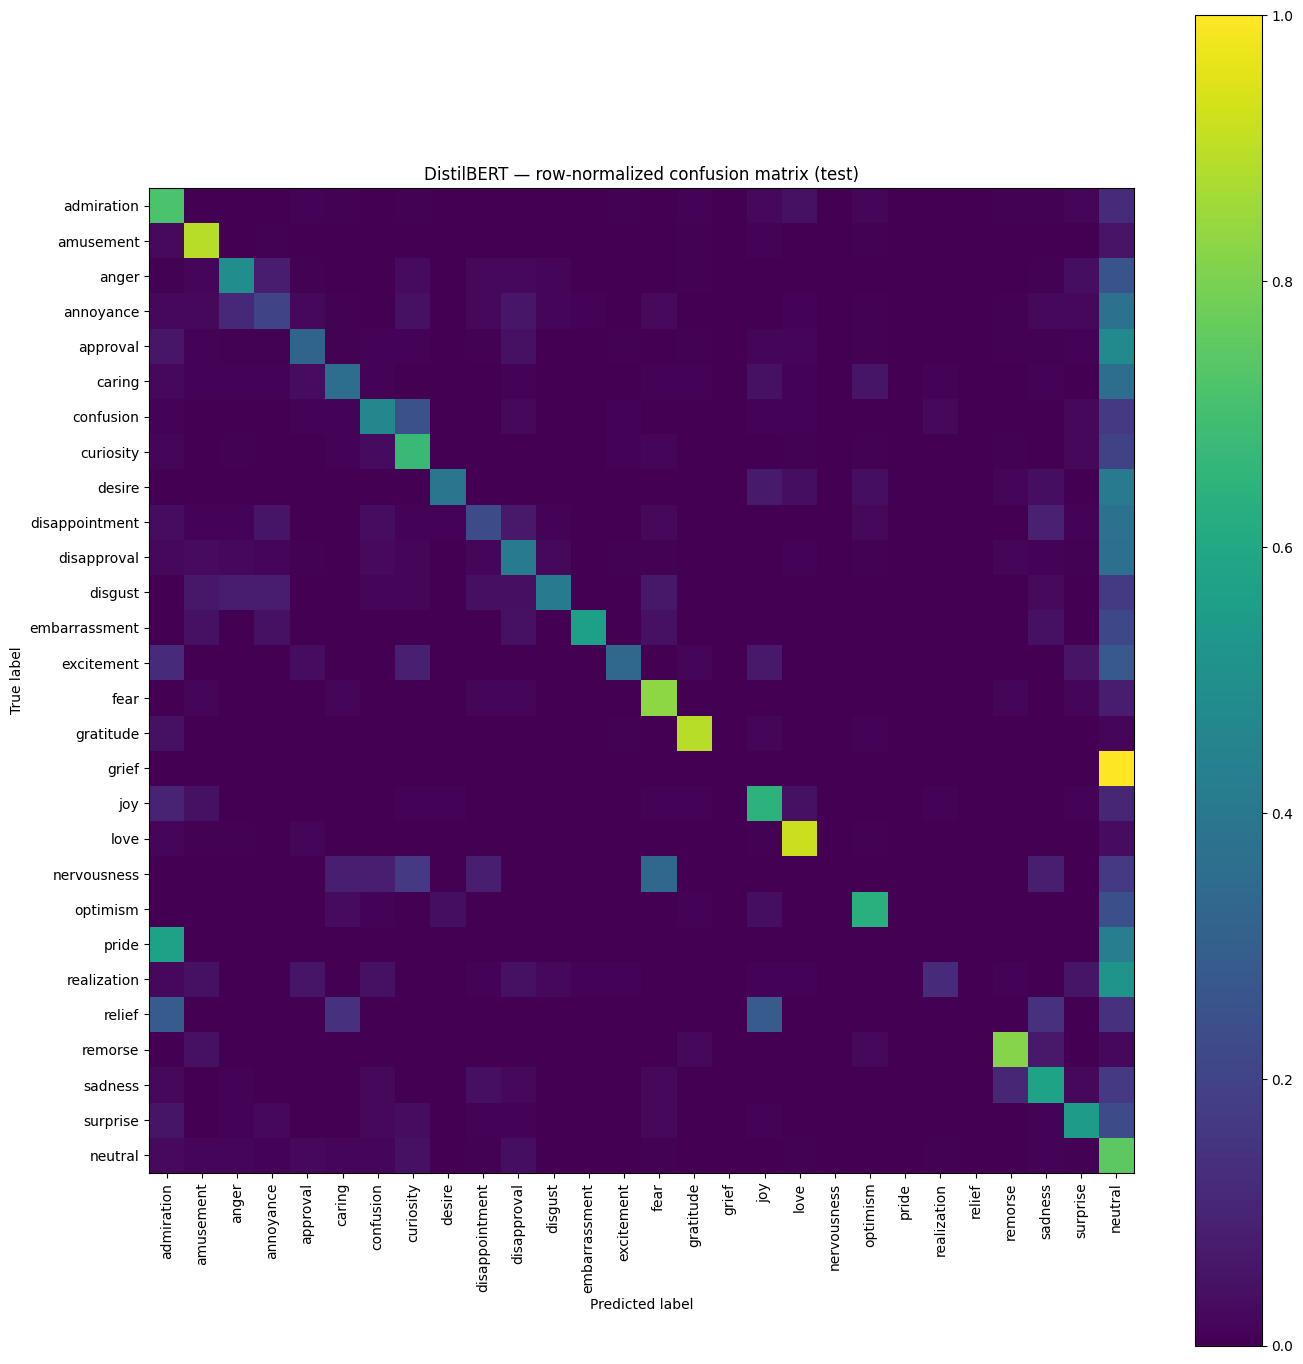

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
Path('results').mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(
    y, bert_pred, display_labels=names, normalize='true',
    include_values=False, xticks_rotation=90, colorbar=True, ax=ax)
ax.set_title('DistilBERT — row-normalized confusion matrix (test)')
plt.tight_layout(); plt.savefig('results/confusion_matrix.png', dpi=120); plt.show()

In [28]:
test_df['true'] = [names[i] for i in y]
test_df['pred'] = [names[i] for i in bert_pred]
mistakes = test_df[test_df.true != test_df.pred].sample(30, random_state=0)
mistakes = mistakes[['text', 'true', 'pred']].assign(my_call='', notes='')

pd.set_option('display.max_colwidth', None)
results.to_csv('results/per_class_f1.csv')
mistakes.to_csv('results/mistakes_30.csv', index=False)
#mistakes


In [40]:
m = pd.read_csv('https://raw.githubusercontent.com/topaztor/goemotionsClassifier/main/results/mistakes_30.csv')
m.columns = m.columns.str.strip().str.lower()
pd.set_option('display.max_colwidth', None)

display(m.my_call.value_counts())
m.sort_values('my_call')

my_call
label_wrong    14
model_wrong     8
both_wrong      5
ambiguous       3
Name: count, dtype: int64

,text,true,pred,my_call,notes
20,Isn't she like a worse version of [NAME]? I always hear from everyone that she is pretty trash.,disgust,annoyance,ambiguous,Could be both
10,Omg I just looked it up and all the places look so beautiful there 😍 also I’m sorry that it’s homophobic,admiration,remorse,ambiguous,NaN
8,"We've been pretty good for the most part the last 5 years. I mean, [NAME] saying [NAME] betrayed him isn't ideal but could be worse.",approval,neutral,ambiguous,NaN
0,"Funny how some people criticize people for not following those laws, when they don't either.",neutral,amusement,both_wrong,sarcasm
27,I'm replying just bask in the glow with someone else! Yay!!,approval,neutral,both_wrong,I think more excitement than anything but could be approval
22,"Now I know where to do stag party for my friend, finally.",approval,neutral,both_wrong,relief
14,There is also no dog in the white house. Why? Because dogs can smell an asshole a mile away.,approval,anger,both_wrong,Im not sure what this is but I know its not these
1,"I totally thought the same thing! I was like, oh honey nooooo!",neutral,realization,both_wrong,disapproval
29,I've found that carrying 21 chromosome's is the sweet spot,realization,neutral,label_wrong,NaN
9,"Maybe they'll change their mind one day! That sounds good, I'll give it a go some time!",admiration,optimism,label_wrong,NaN


In [41]:
(lr_pred == y).mean() and (bert_pred == y).mean()

np.float64(0.6296296296296297)

In [42]:
from sklearn.metrics import confusion_matrix

print("Baseline accuracy:  ", round((lr_pred == y).mean(), 3))
print("DistilBERT accuracy:", round((bert_pred == y).mean(), 3))

cm = pd.DataFrame(confusion_matrix(y, bert_pred, normalize='true'), index=names, columns=names)
print("Approval → neutral:   ", f"{cm.loc['approval', 'neutral']:.0%}")
print("Disapproval → neutral:", f"{cm.loc['disapproval', 'neutral']:.0%}")

Baseline accuracy:   0.502
DistilBERT accuracy: 0.63
Approval → neutral:    47%
Disapproval → neutral: 36%


In [19]:
from kaggle_secrets import UserSecretsClient
import subprocess
token = UserSecretsClient().get_secret("GITHUB_TOKEN")
repo = "topaztor/goemotionsClassifier"

!rm -rf repo && git clone -q https://{token}@github.com/{repo}.git repo
!mkdir -p repo/results && cp results/* repo/results/

r = subprocess.run(
    'cd repo && git config user.name "topaztor" '
    '&& git config user.email "topaztor@users.noreply.github.com" '
    '&& git add results && git commit -m "Add results" && git push -q',
    shell=True, capture_output=True, text=True)
print(r.stdout, r.stderr)
print("✅ Pushed" if r.returncode == 0 else "❌ Push failed")

[main 051bc4e] Add results
 3 files changed, 61 insertions(+)
 create mode 100644 results/confusion_matrix.png
 create mode 100644 results/mistakes_30.csv
 create mode 100644 results/per_class_f1.csv
 
✅ Pushed
